In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = "../data/processed/clean_sessions.csv"
FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# parse_dates turns the saved text back into real datetimes
df = pd.read_csv(DATA_PATH, parse_dates=["StartDatetime", "EndDatetime"])
print(df.shape)     # expect about (72826, 14)


def save_fig(name):
    """Tidy the layout, save the chart for the README/presentation, then show it."""
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

(72826, 14)


In [3]:
import importlib

for lib in ["sklearn", "xgboost", "lightgbm", "imblearn", "shap", "lime", "statsmodels", "streamlit"]:
    try:
        module = importlib.import_module(lib)
        print(f"{lib:12s} OK  {getattr(module, '__version__', '')}")
    except Exception as error:
        print(f"{lib:12s} FAILED -> {error}")

sklearn      OK  1.9.1
xgboost      OK  3.4.1
lightgbm     OK  4.7.0
imblearn     OK  0.14.2
shap         OK  0.54.1
lime         OK  
statsmodels  OK  0.15.0
streamlit    OK  1.66.1


In [4]:
print("Sessions:", f"{len(df):,}")
print("Chargers:", df["ChargerID"].nunique())
print("Known users:", df.loc[df["IsKnownUser"], "UserID"].nunique())
print("Period:", df["StartDatetime"].min().date(), "to", df["StartDatetime"].max().date())
print("Total demand (assumed kWh):", round(df["Demand"].sum()))
print("Mean demand:", round(df["Demand"].mean(), 2), "| Median:", df["Demand"].median())

Sessions: 72,826
Chargers: 2118
Known users: 2336
Period: 2021-09-30 to 2022-09-30
Total demand (assumed kWh): 1270112
Mean demand: 17.44 | Median: 14.1


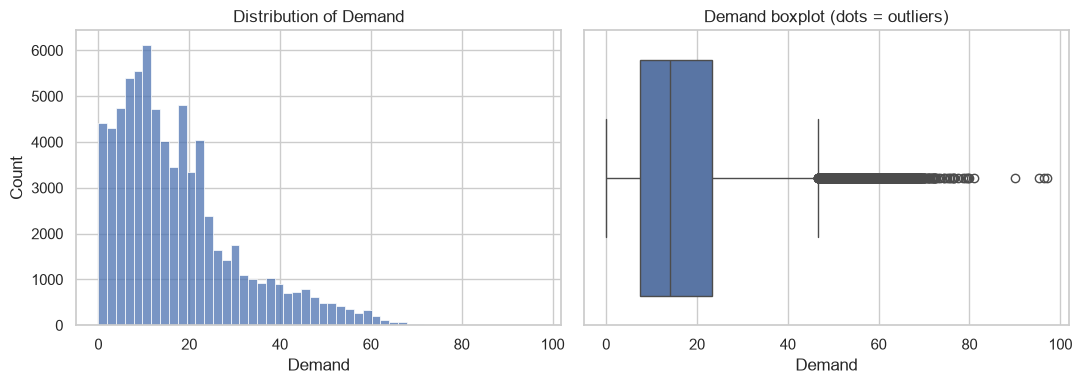

Skewness of Demand: 1.19
Skewness of DurationCalc: 3.33


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["Demand"], bins=50, ax=axes[0])
axes[0].set_title("Distribution of Demand")

sns.boxplot(x=df["Demand"], ax=axes[1])
axes[1].set_title("Demand boxplot (dots = outliers)")
save_fig("01_demand_distribution")

print("Skewness of Demand:", round(df["Demand"].skew(), 2))
print("Skewness of DurationCalc:", round(df["DurationCalc"].skew(), 2))

                  sessions  mean_demand  median_demand
ChargerTypeLabel                                      
Type 0               57896        17.05          13.10
Type 1               14930        18.95          17.15 

                     sessions  mean_demand  median_demand
ChargerCompanyLabel                                      
Company 0               27117        16.69          13.29
Company 1               45709        17.89          14.65 



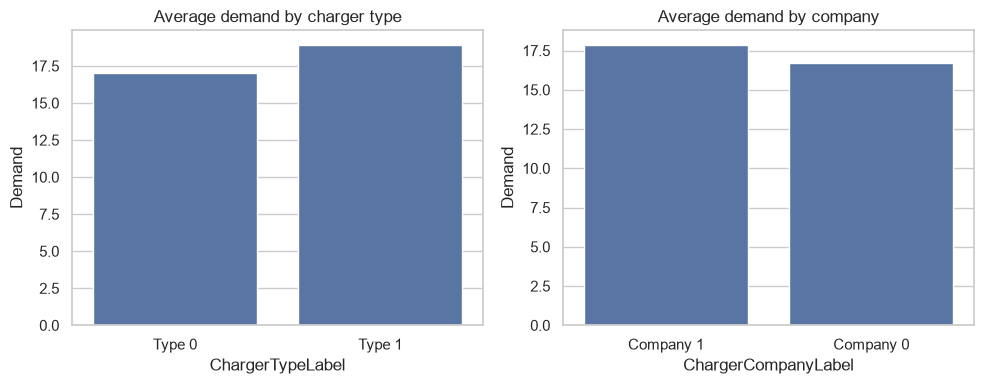

In [6]:
for column in ["ChargerTypeLabel", "ChargerCompanyLabel"]:
    summary = df.groupby(column)["Demand"].agg(sessions="size", mean_demand="mean", median_demand="median").round(2)
    print(summary, "\n")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x="ChargerTypeLabel", y="Demand", ax=axes[0], errorbar=None)
axes[0].set_title("Average demand by charger type")
sns.barplot(data=df, x="ChargerCompanyLabel", y="Demand", ax=axes[1], errorbar=None)
axes[1].set_title("Average demand by company")
save_fig("02_demand_by_type_company")

                    sessions  mean_demand
Location                                 
accommodation            187        29.06
bus garage                29        28.59
camping                 1630        25.53
apartment              14036        18.74
public area            14076        17.90
restaurant              2222        17.81
public institution      7023        17.40
resort                  8854        17.28
public parking lot      3394        17.19
golf                    1029        16.72
market                  2988        16.51
company                 7557        16.25
sightseeing             1203        15.25
hotel                   8598        14.70


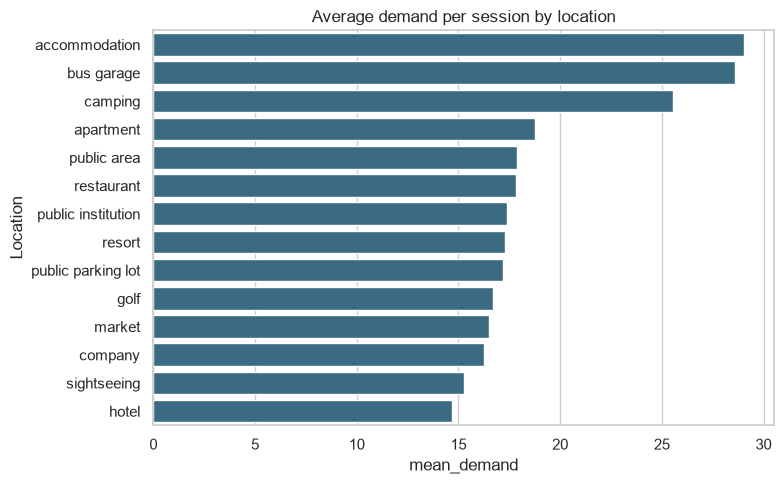

In [7]:
location_summary = (
    df.groupby("Location")["Demand"]
    .agg(sessions="size", mean_demand="mean")
    .round(2)
    .sort_values("mean_demand", ascending=False)
)
print(location_summary)

plt.figure(figsize=(8, 5))
sns.barplot(data=location_summary.reset_index(), x="mean_demand", y="Location", color="#2F6F8F")
plt.title("Average demand per session by location")
save_fig("03_demand_by_location")

C:\Users\yoges\AppData\Local\Temp\ipykernel_15552\2073741149.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek      # Monday = 0 ... Sunday = 6


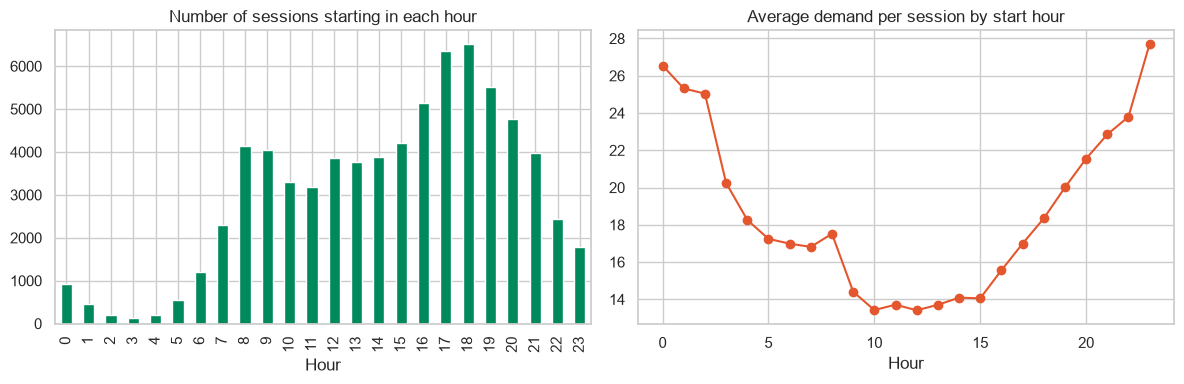

            size   mean
IsWeekend              
False      53901  17.38
True       18925  17.60


In [8]:
# Temporary time columns for EDA. We formalise them on Day 4 (feature engineering)
df["Hour"] = df["StartDatetime"].dt.hour
df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek      # Monday = 0 ... Sunday = 6
df["IsWeekend"] = df["DayOfWeek"] >= 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sessions_by_hour = df.groupby("Hour").size()
sessions_by_hour.plot(kind="bar", ax=axes[0], color="#00895C")
axes[0].set_title("Number of sessions starting in each hour")

demand_by_hour = df.groupby("Hour")["Demand"].mean()
demand_by_hour.plot(kind="line", marker="o", ax=axes[1], color="#E4572E")
axes[1].set_title("Average demand per session by start hour")
save_fig("04_hourly_patterns")

print(df.groupby("IsWeekend")["Demand"].agg(["size", "mean"]).round(2))

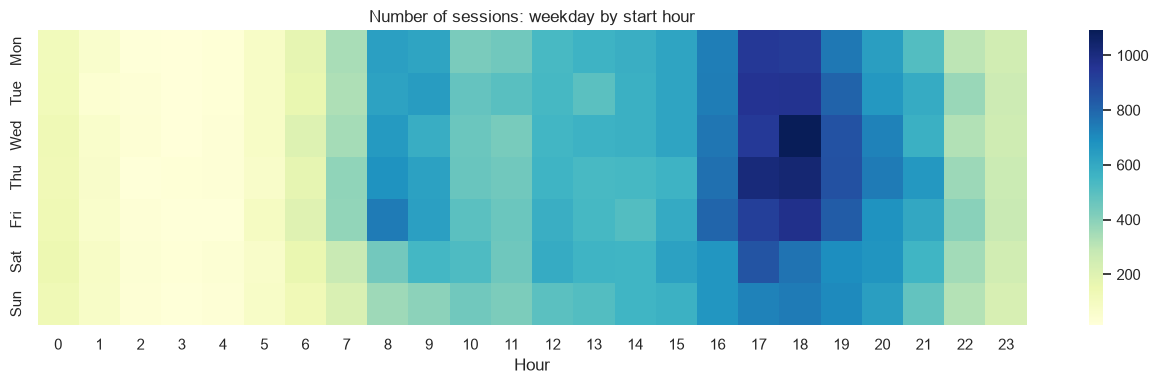

In [9]:
busy = df.pivot_table(index="DayOfWeek", columns="Hour", values="Demand", aggfunc="size")
busy.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(13, 4))
sns.heatmap(busy, cmap="YlGnBu")
plt.title("Number of sessions: weekday by start hour")
save_fig("05_weekday_hour_heatmap")

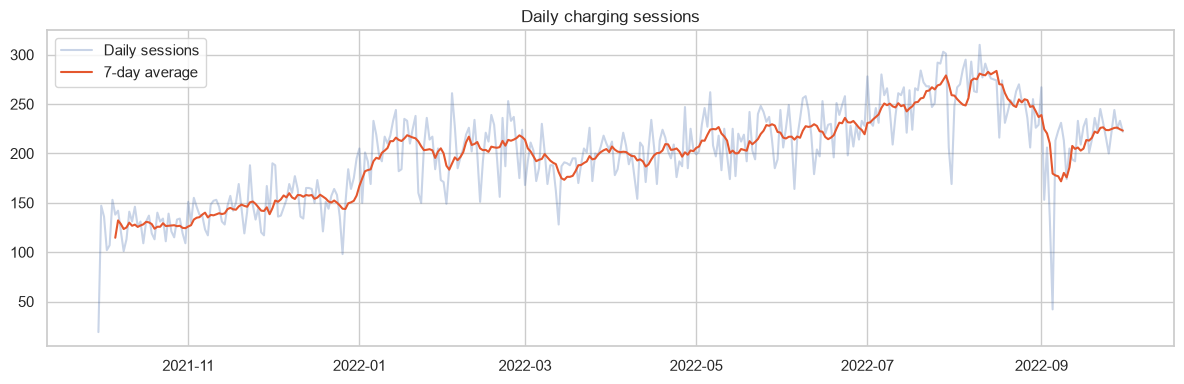

Days in series: 366 | days with zero sessions: 0


In [10]:
daily = df.set_index("StartDatetime").resample("D").agg(
    sessions=("Demand", "size"),
    total_demand=("Demand", "sum"),
)
daily["sessions_7day_avg"] = daily["sessions"].rolling(7).mean()

plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily["sessions"], alpha=0.3, label="Daily sessions")
plt.plot(daily.index, daily["sessions_7day_avg"], color="#E4572E", label="7-day average")
plt.title("Daily charging sessions")
plt.legend()
save_fig("06_daily_trend")

print("Days in series:", len(daily), "| days with zero sessions:", (daily["sessions"] == 0).sum())

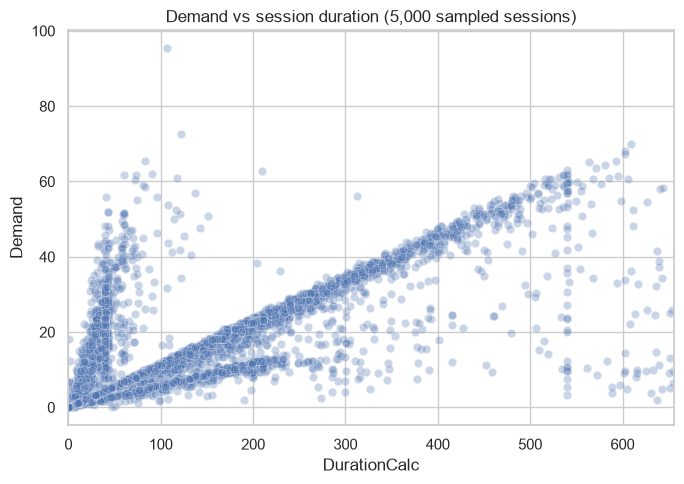

Correlation: 0.604
              size   mean
IsKnownUser              
False        31553  16.63
True         41273  18.06


In [11]:
sample = df.sample(5000, random_state=42)       # plot a sample so it stays readable
plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="DurationCalc", y="Demand", alpha=0.3)
plt.xlim(0, df["DurationCalc"].quantile(0.99))
plt.title("Demand vs session duration (5,000 sampled sessions)")
save_fig("07_demand_vs_duration")

print("Correlation:", round(df["Demand"].corr(df["DurationCalc"]), 3))
print(df.groupby("IsKnownUser")["Demand"].agg(["size", "mean"]).round(2))

count    2118.0
mean       34.4
std        75.7
min         1.0
25%         3.0
50%         9.0
75%        26.0
max       674.0
Name: count, dtype: float64
Share of chargers with fewer than 10 sessions: 0.524
Share of all sessions at the busiest 10% of chargers: 0.63


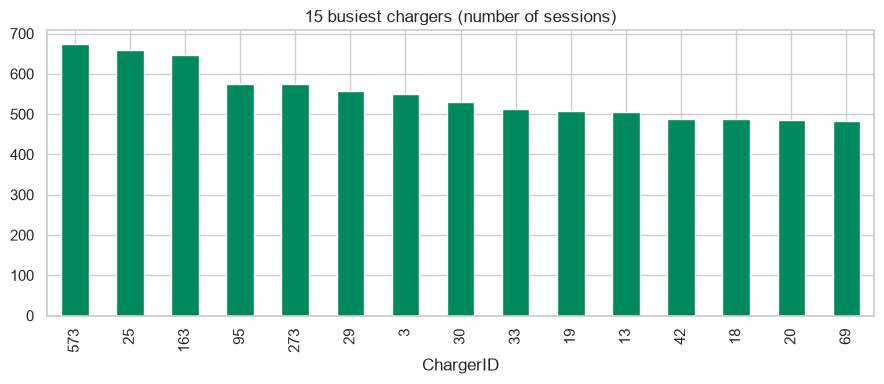

In [12]:
sessions_per_charger = df["ChargerID"].value_counts()

print(sessions_per_charger.describe().round(1))
print("Share of chargers with fewer than 10 sessions:", round((sessions_per_charger < 10).mean(), 3))
top_10_percent = int(len(sessions_per_charger) * 0.10)
print("Share of all sessions at the busiest 10% of chargers:",
      round(sessions_per_charger.head(top_10_percent).sum() / sessions_per_charger.sum(), 3))

plt.figure(figsize=(9, 4))
sessions_per_charger.head(15).plot(kind="bar", color="#00895C")
plt.title("15 busiest chargers (number of sessions)")
plt.xlabel("ChargerID")
save_fig("08_busiest_chargers")

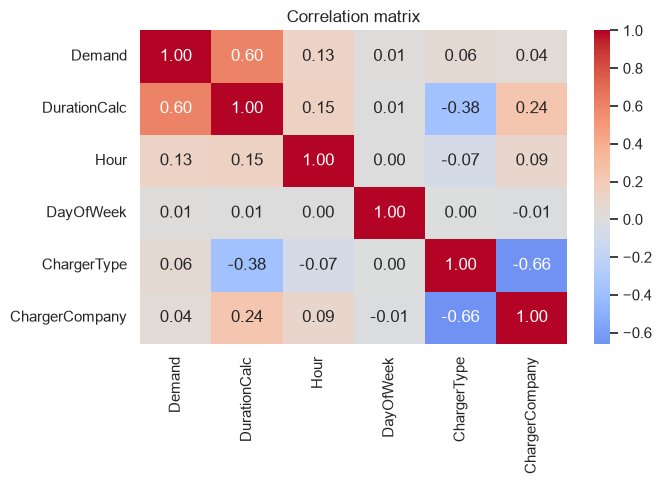

In [13]:
numeric_columns = ["Demand", "DurationCalc", "Hour", "DayOfWeek", "ChargerType", "ChargerCompany"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save_fig("09_correlation_matrix")